In [1]:
import sys
sys.path.append("..")

from src.data import make_dataset, CLASSES, data_augmentation

train_ds = make_dataset("train", augment=True)
val_ds = make_dataset("val")
test_ds = make_dataset("test")

images, labels = next(iter(train_ds))
print(images.shape, labels.numpy()[:10])
print("batches -> train:", len(train_ds), "| val:", len(val_ds), "| test:", len(test_ds))

I0000 00:00:1792962281.893258   57908 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792962281.894330   57908 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792962282.131432   57908 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792962283.325066   57908 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

(32, 224, 224, 3) [3 1 1 0 3 2 1 0 0 1]
batches -> train: 91 | val: 16 | test: 16


In [2]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

# base: ImageNet weights, no top layer
base = MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights="imagenet")
base.trainable = False          # freeze

# head: 4 classes
inputs = layers.Input(shape=(224, 224, 3))
x = base(inputs, training=False)            # keep BatchNorm in inference mode
x = layers.GlobalAveragePooling2D()(x)      # (7,7,1280) -> (1280)
x = layers.Dropout(0.3)(x)                  # turn off 30% of neurons while training
outputs = layers.Dense(4, activation="softmax")(x)

model = models.Model(inputs, outputs)
model.summary()

print("trainable weights:", sum(tf.size(w).numpy() for w in model.trainable_weights))
print("frozen weights:   ", sum(tf.size(w).numpy() for w in model.non_trainable_weights))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 10s 1us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

trainable weights: 5124
frozen weights:    2257984


In [3]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
)

Epoch 1/5


/home/amine/anaconda3/envs/ai/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


91/91 ━━━━━━━━━━━━━━━━━━━━ 50s 528ms/step - accuracy: 0.6336 - loss: 0.8969 - val_accuracy: 0.6855 - val_loss: 0.7685
Epoch 2/5
91/91 ━━━━━━━━━━━━━━━━━━━━ 49s 534ms/step - accuracy: 0.7988 - loss: 0.5251 - val_accuracy: 0.7157 - val_loss: 0.7119
Epoch 3/5
91/91 ━━━━━━━━━━━━━━━━━━━━ 54s 590ms/step - accuracy: 0.8299 - loss: 0.4429 - val_accuracy: 0.7621 - val_loss: 0.5985
Epoch 4/5
91/91 ━━━━━━━━━━━━━━━━━━━━ 50s 540ms/step - accuracy: 0.8389 - loss: 0.4037 - val_accuracy: 0.7339 - val_loss: 0.6832
Epoch 5/5
91/91 ━━━━━━━━━━━━━━━━━━━━ 47s 516ms/step - accuracy: 0.8534 - loss: 0.3770 - val_accuracy: 0.7460 - val_loss: 0.6480


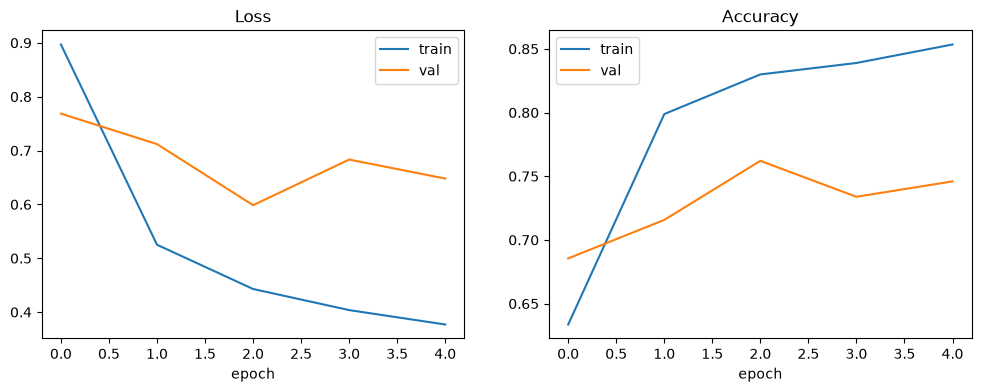

16/16 ━━━━━━━━━━━━━━━━━━━━ 8s 435ms/step
              precision    recall  f1-score   support

      Glioma      0.888     0.644     0.747       135
  Meningioma      0.675     0.619     0.646       134
    No Tumor      0.985     0.703     0.821        91
   Pituitary      0.648     1.000     0.786       136

    accuracy                          0.746       496
   macro avg      0.799     0.742     0.750       496
weighted avg      0.782     0.746     0.744       496

[[ 87  29   0  19]
 [  9  83   1  41]
 [  2  11  64  14]
 [  0   0   0 136]]


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

# 1. learning curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["loss"], label="train")
axes[0].plot(history.history["val_loss"], label="val")
axes[0].set_title("Loss"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].plot(history.history["accuracy"], label="train")
axes[1].plot(history.history["val_accuracy"], label="val")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("epoch"); axes[1].legend()
plt.show()

# 2. per-class results on Val (val_ds is not shuffled, so the order is stable)
y_true = np.concatenate([y.numpy() for _, y in val_ds])
y_pred = np.argmax(model.predict(val_ds), axis=1)

print(classification_report(y_true, y_pred, target_names=CLASSES, digits=3))
print(confusion_matrix(y_true, y_pred))

In [5]:
import os
os.makedirs("../models", exist_ok=True)

callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint("../models/mobilenet_head.keras", monitor="val_loss", save_best_only=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1),
]

# rebuild the same model so we start fresh
base = MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights="imagenet")
base.trainable = False

inputs = layers.Input(shape=(224, 224, 3))
x = base(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(4, activation="softmax")(x)
model = models.Model(inputs, outputs)

model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])

history_head = model.fit(train_ds, validation_data=val_ds, epochs=15, callbacks=callbacks)

Epoch 1/15


/home/amine/anaconda3/envs/ai/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


91/91 ━━━━━━━━━━━━━━━━━━━━ 53s 542ms/step - accuracy: 0.6260 - loss: 0.9192 - val_accuracy: 0.7339 - val_loss: 0.6391 - learning_rate: 0.0010
Epoch 2/15
91/91 ━━━━━━━━━━━━━━━━━━━━ 48s 521ms/step - accuracy: 0.7902 - loss: 0.5406 - val_accuracy: 0.7379 - val_loss: 0.6255 - learning_rate: 0.0010
Epoch 3/15
91/91 ━━━━━━━━━━━━━━━━━━━━ 48s 519ms/step - accuracy: 0.8241 - loss: 0.4614 - val_accuracy: 0.7762 - val_loss: 0.5585 - learning_rate: 0.0010
Epoch 4/15
91/91 ━━━━━━━━━━━━━━━━━━━━ 47s 516ms/step - accuracy: 0.8292 - loss: 0.4108 - val_accuracy: 0.7440 - val_loss: 0.6331 - learning_rate: 0.0010
Epoch 5/15
91/91 ━━━━━━━━━━━━━━━━━━━━ 48s 518ms/step - accuracy: 0.8417 - loss: 0.4008 - val_accuracy: 0.7581 - val_loss: 0.5368 - learning_rate: 0.0010
Epoch 6/15
91/91 ━━━━━━━━━━━━━━━━━━━━ 47s 516ms/step - accuracy: 0.8566 - loss: 0.3807 - val_accuracy: 0.7601 - val_loss: 0.5569 - learning_rate: 0.0010
Epoch 7/15
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 443ms/step - accuracy: 0.8735 - loss: 0.3449
Epoch 7

In [6]:
# unfreeze the last 30 layers of the base
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

print("trainable weights:", sum(tf.size(w).numpy() for w in model.trainable_weights))

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

callbacks_ft = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint("../models/mobilenet_finetuned.keras", monitor="val_loss", save_best_only=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1),
]

history_ft = model.fit(train_ds, validation_data=val_ds, epochs=10, callbacks=callbacks_ft)

trainable weights: 1515844
Epoch 1/10
91/91 ━━━━━━━━━━━━━━━━━━━━ 55s 579ms/step - accuracy: 0.8707 - loss: 0.3366 - val_accuracy: 0.7944 - val_loss: 0.5041 - learning_rate: 1.0000e-05
Epoch 2/10
91/91 ━━━━━━━━━━━━━━━━━━━━ 52s 569ms/step - accuracy: 0.8887 - loss: 0.2754 - val_accuracy: 0.8145 - val_loss: 0.4573 - learning_rate: 1.0000e-05
Epoch 3/10
91/91 ━━━━━━━━━━━━━━━━━━━━ 52s 565ms/step - accuracy: 0.8960 - loss: 0.2608 - val_accuracy: 0.8024 - val_loss: 0.5080 - learning_rate: 1.0000e-05
Epoch 4/10
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 526ms/step - accuracy: 0.9081 - loss: 0.2407
Epoch 4: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
91/91 ━━━━━━━━━━━━━━━━━━━━ 57s 617ms/step - accuracy: 0.9081 - loss: 0.2407 - val_accuracy: 0.7903 - val_loss: 0.5216 - learning_rate: 1.0000e-05
Epoch 5/10
91/91 ━━━━━━━━━━━━━━━━━━━━ 58s 634ms/step - accuracy: 0.9150 - loss: 0.2229 - val_accuracy: 0.8468 - val_loss: 0.3768 - learning_rate: 5.0000e-06
Epoch 6/10
91/91 ━━━━━━━━━━━━━━━━━━━━

In [7]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

best_model = tf.keras.models.load_model("../models/mobilenet_finetuned.keras")

y_true = np.concatenate([y.numpy() for _, y in val_ds])
y_pred = np.argmax(best_model.predict(val_ds), axis=1)

print(classification_report(y_true, y_pred, target_names=CLASSES, digits=3))
print(confusion_matrix(y_true, y_pred))

16/16 ━━━━━━━━━━━━━━━━━━━━ 8s 443ms/step
              precision    recall  f1-score   support

      Glioma      0.954     0.763     0.848       135
  Meningioma      0.785     0.843     0.813       134
    No Tumor      0.964     0.879     0.920        91
   Pituitary      0.832     0.985     0.902       136

    accuracy                          0.867       496
   macro avg      0.884     0.868     0.871       496
weighted avg      0.877     0.867     0.866       496

[[103  24   0   8]
 [  2 113   2  17]
 [  3   6  80   2]
 [  0   1   1 134]]


In [8]:
from tensorflow.keras import regularizers

def build_model(dropout, l2):
    base = MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights="imagenet")
    base.trainable = False
    inputs = layers.Input(shape=(224, 224, 3))
    x = base(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    reg = regularizers.l2(l2) if l2 > 0 else None
    outputs = layers.Dense(4, activation="softmax", kernel_regularizer=reg)(x)
    return models.Model(inputs, outputs), base

def get_callbacks(path):
    return [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
        tf.keras.callbacks.ModelCheckpoint(path, monitor="val_loss", save_best_only=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1),
    ]

def train_config(name, dropout, l2):
    model, base = build_model(dropout, l2)

    # phase 1: head
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=15,
                   callbacks=get_callbacks(f"../models/{name}_head.keras"))

    # phase 2: fine-tuning (last 30 layers, BatchNorm frozen)
    base.trainable = True
    for layer in base.layers[:-30]:
        layer.trainable = False
    for layer in base.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=10,
                   callbacks=get_callbacks(f"../models/{name}_finetuned.keras"))
    return h1, h2

h1_b, h2_b = train_config("config_b", dropout=0.5, l2=1e-4)

Epoch 1/15


/home/amine/anaconda3/envs/ai/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


91/91 ━━━━━━━━━━━━━━━━━━━━ 53s 562ms/step - accuracy: 0.5842 - loss: 1.0606 - val_accuracy: 0.7016 - val_loss: 0.7574 - learning_rate: 0.0010
Epoch 2/15
91/91 ━━━━━━━━━━━━━━━━━━━━ 51s 549ms/step - accuracy: 0.7518 - loss: 0.6390 - val_accuracy: 0.7298 - val_loss: 0.6715 - learning_rate: 0.0010
Epoch 3/15
91/91 ━━━━━━━━━━━━━━━━━━━━ 50s 546ms/step - accuracy: 0.7853 - loss: 0.5474 - val_accuracy: 0.7460 - val_loss: 0.6607 - learning_rate: 0.0010
Epoch 4/15
91/91 ━━━━━━━━━━━━━━━━━━━━ 50s 539ms/step - accuracy: 0.8161 - loss: 0.4795 - val_accuracy: 0.7500 - val_loss: 0.6509 - learning_rate: 0.0010
Epoch 5/15
91/91 ━━━━━━━━━━━━━━━━━━━━ 50s 547ms/step - accuracy: 0.8182 - loss: 0.4571 - val_accuracy: 0.7560 - val_loss: 0.6088 - learning_rate: 0.0010
Epoch 6/15
91/91 ━━━━━━━━━━━━━━━━━━━━ 49s 534ms/step - accuracy: 0.8247 - loss: 0.4415 - val_accuracy: 0.7621 - val_loss: 0.6151 - learning_rate: 0.0010
Epoch 7/15
91/91 ━━━━━━━━━━━━━━━━━━━━ 53s 578ms/step - accuracy: 0.8268 - loss: 0.4382 - val_

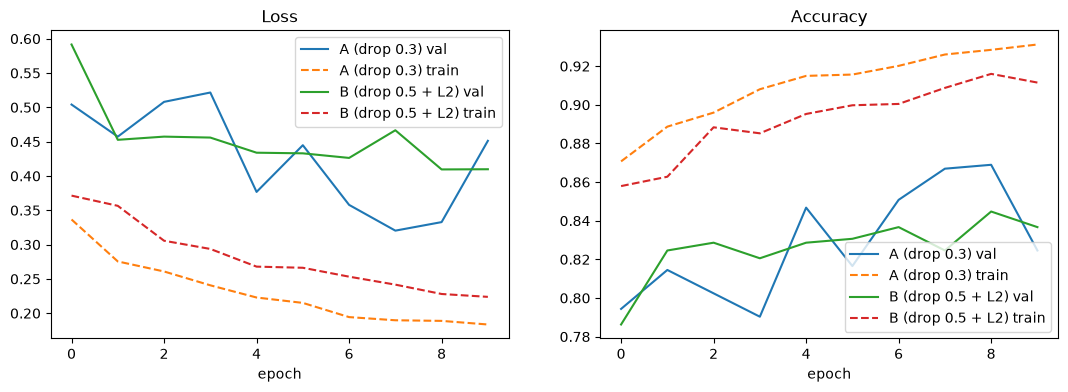


===== Config A =====
              precision    recall  f1-score   support

      Glioma      0.954     0.763     0.848       135
  Meningioma      0.785     0.843     0.813       134
    No Tumor      0.964     0.879     0.920        91
   Pituitary      0.832     0.985     0.902       136

    accuracy                          0.867       496
   macro avg      0.884     0.868     0.871       496
weighted avg      0.877     0.867     0.866       496


===== Config B =====
              precision    recall  f1-score   support

      Glioma      0.933     0.719     0.812       135
  Meningioma      0.783     0.806     0.794       134
    No Tumor      1.000     0.857     0.923        91
   Pituitary      0.773     1.000     0.872       136

    accuracy                          0.845       496
   macro avg      0.872     0.845     0.850       496
weighted avg      0.861     0.845     0.844       496



In [9]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

# curves: A = history_ft, B = h2_b (fine-tuning phase)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, h in [("A (drop 0.3)", history_ft), ("B (drop 0.5 + L2)", h2_b)]:
    axes[0].plot(h.history["val_loss"], label=f"{name} val")
    axes[0].plot(h.history["loss"], "--", label=f"{name} train")
    axes[1].plot(h.history["val_accuracy"], label=f"{name} val")
    axes[1].plot(h.history["accuracy"], "--", label=f"{name} train")
axes[0].set_title("Loss"); axes[1].set_title("Accuracy")
for ax in axes:
    ax.set_xlabel("epoch"); ax.legend()
plt.show()

# reports on Val, best saved model of each config
y_true = np.concatenate([y.numpy() for _, y in val_ds])
for name, path in [("A", "../models/mobilenet_finetuned.keras"),
                   ("B", "../models/config_b_finetuned.keras")]:
    m = tf.keras.models.load_model(path)
    y_pred = np.argmax(m.predict(val_ds, verbose=0), axis=1)
    print(f"\n===== Config {name} =====")
    print(classification_report(y_true, y_pred, target_names=CLASSES, digits=3))